In [ ]:
# Arpit Huss (E23CSEU0554)

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

IMG_SIZE = 128

In [3]:
!pip -q install kagglehub

import kagglehub

dataset_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print(dataset_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia


In [4]:
data_root = None

for root, dirs, files in os.walk(dataset_path):
    if "train" in dirs and "test" in dirs:
        data_root = root
        break

train_dir = os.path.join(data_root, "train")
test_dir = os.path.join(data_root, "test")

print("Dataset path:", data_root)

Dataset path: /kaggle/input/chest-xray-pneumonia/chest_xray


In [5]:
classes = ["NORMAL", "PNEUMONIA"]

files = []

for folder in [train_dir, test_dir]:
    for class_name in classes:
        class_path = os.path.join(folder, class_name)

        for file in os.listdir(class_path):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                files.append([
                    os.path.join(class_path, file),
                    class_name
                ])

df = pd.DataFrame(files, columns=["path", "class"])

df["label"] = df["class"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
})

print("Total images:", len(df))
print(df["class"].value_counts())

Total images: 5840
class
PNEUMONIA    4265
NORMAL       1575
Name: count, dtype: int64


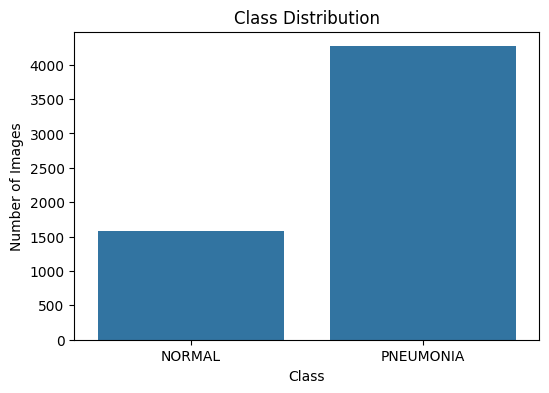

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

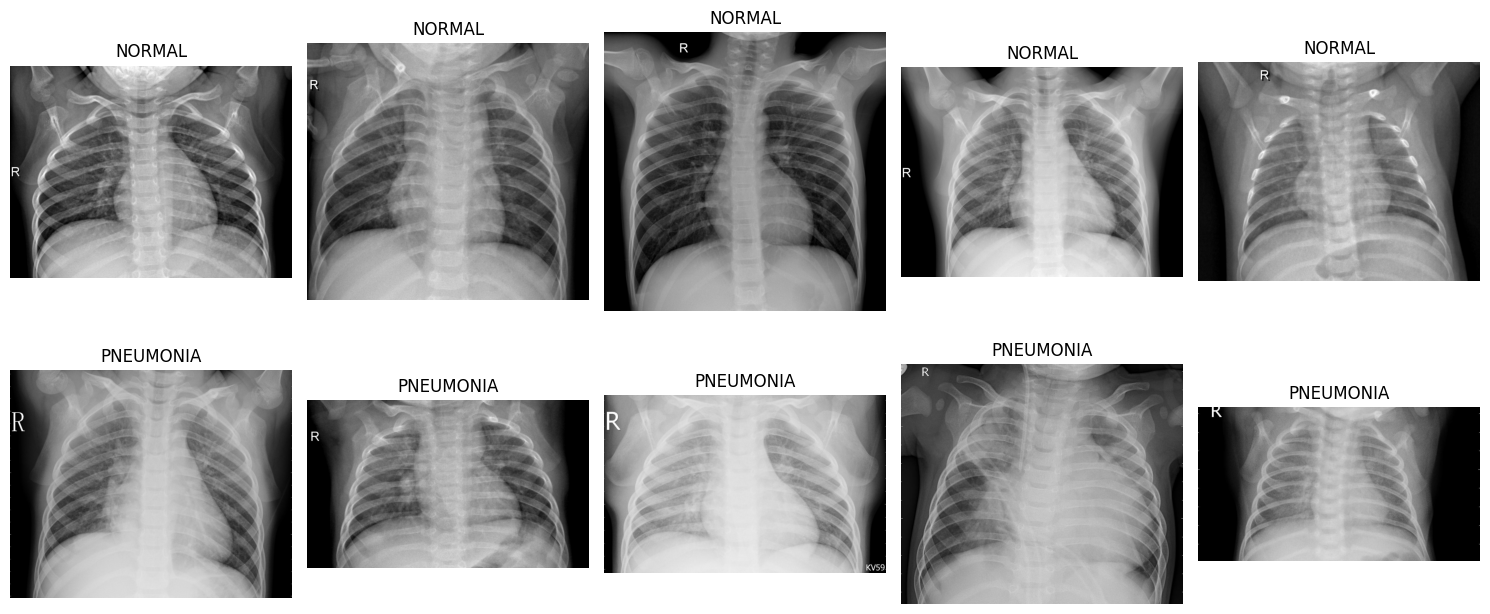

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, class_name in enumerate(classes):

    samples = df[df["class"] == class_name].sample(
        5,
        random_state=42
    )

    for col, (_, item) in enumerate(samples.iterrows()):

        img = Image.open(item["path"]).convert("L")

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [8]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 4088
Validation: 876
Testing: 876


In [9]:
def load_image(path):
    img = Image.open(path).convert("L")
    img = img.resize((IMG_SIZE, IMG_SIZE))
    return np.array(img, dtype=np.float32) / 255.0

In [10]:
from skimage.feature import hog
from skimage.feature import local_binary_pattern
from skimage.feature import graycomatrix, graycoprops

def extract_features(path):

    img = load_image(path)

    hog_features = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    img_uint = (img * 255).astype(np.uint8)

    lbp = local_binary_pattern(
        img_uint,
        P=8,
        R=1,
        method="uniform"
    )

    lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 11),
        range=(0, 10)
    )

    lbp_hist = lbp_hist.astype(np.float32)
    lbp_hist = lbp_hist / (lbp_hist.sum() + 1e-8)

    small_img = (img_uint // 32).astype(np.uint8)

    glcm = graycomatrix(
        small_img,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=8,
        symmetric=True,
        normed=True
    )

    glcm_features = []

    for feature in [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation"
    ]:
        glcm_features.extend(
            graycoprops(glcm, feature).ravel()
        )

    return np.concatenate([
        hog_features,
        lbp_hist,
        np.array(glcm_features)
    ])

In [11]:
features = []
labels = []

for i, row in df.iterrows():

    try:
        f = extract_features(row["path"])
        features.append(f)
        labels.append(row["label"])
    except:
        pass

X_features = np.array(features, dtype=np.float32)
y_features = np.array(labels)

print("Feature matrix:", X_features.shape)
print("Labels:", y_features.shape)

Feature matrix: (5840, 1794)
Labels: (5840,)


In [12]:
def prepare_images(data):

    images = []
    labels = []

    for _, row in data.iterrows():

        try:
            img = load_image(row["path"])
            images.append(img)
            labels.append(row["label"])
        except:
            pass

    images = np.array(images, dtype=np.float32)
    images = images[..., np.newaxis]

    return images, np.array(labels)


X_train, y_train = prepare_images(train_df)
X_val, y_val = prepare_images(val_df)
X_test, y_test = prepare_images(test_df)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(4088, 128, 128, 1)
(876, 128, 128, 1)
(876, 128, 128, 1)


In [13]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

def create_model(filters=32, dropout=0.3, lr=0.001):

    model = Sequential([
        Conv2D(
            filters,
            (3, 3),
            activation="relu",
            padding="same",
            input_shape=(128, 128, 1)
        ),

        MaxPooling2D(2, 2),

        Conv2D(
            filters * 2,
            (3, 3),
            activation="relu",
            padding="same"
        ),

        MaxPooling2D(2, 2),

        Conv2D(
            filters * 4,
            (3, 3),
            activation="relu",
            padding="same"
        ),

        MaxPooling2D(2, 2),

        Flatten(),

        Dense(128, activation="relu"),
        Dropout(dropout),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [14]:
normal = np.sum(y_train == 0)
pneumonia = np.sum(y_train == 1)

total = normal + pneumonia

class_weight = {
    0: total / (2 * normal),
    1: total / (2 * pneumonia)
}

print(class_weight)

{0: np.float64(1.8548094373865698), 1: np.float64(0.6845277963831212)}


In [15]:
from sklearn.model_selection import StratifiedKFold

settings = [
    (16, 0.3, 0.001),
    (32, 0.3, 0.001),
    (32, 0.5, 0.0005)
]

tune_size = min(2400, len(X_train))

rng = np.random.default_rng(42)

indices = rng.choice(
    len(X_train),
    tune_size,
    replace=False
)

X_tune = X_train[indices]
y_tune = y_train[indices]

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = []

for filters, dropout, lr in settings:

    scores = []

    for train_idx, val_idx in skf.split(
        X_tune,
        y_tune
    ):

        model = create_model(
            filters=filters,
            dropout=dropout,
            lr=lr
        )

        model.fit(
            X_tune[train_idx],
            y_tune[train_idx],
            validation_data=(
                X_tune[val_idx],
                y_tune[val_idx]
            ),
            epochs=4,
            batch_size=32,
            class_weight=class_weight,
            verbose=0
        )

        pred = model.predict(
            X_tune[val_idx],
            verbose=0
        ).ravel()

        pred = (pred >= 0.5).astype(int)

        scores.append(
            accuracy_score(
                y_tune[val_idx],
                pred
            )
        )

    cv_results.append([
        filters,
        dropout,
        lr,
        np.mean(scores)
    ])

cv_results = pd.DataFrame(
    cv_results,
    columns=[
        "Filters",
        "Dropout",
        "Learning Rate",
        "CV Accuracy"
    ]
)

print(cv_results)

best = cv_results.loc[
    cv_results["CV Accuracy"].idxmax()
]

print("\nBest configuration:")
print(best)

   Filters  Dropout  Learning Rate  CV Accuracy
0       16      0.3         0.0010     0.935417
1       32      0.3         0.0010     0.914583
2       32      0.5         0.0005     0.930000

Best configuration:
Filters          16.000000
Dropout           0.300000
Learning Rate     0.001000
CV Accuracy       0.935417
Name: 0, dtype: float64


In [16]:
from tensorflow.keras.callbacks import EarlyStopping

model = create_model(
    filters=int(best["Filters"]),
    dropout=float(best["Dropout"]),
    lr=float(best["Learning Rate"])
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 10s 52ms/step - accuracy: 0.8322 - loss: 0.3753 - val_accuracy: 0.9121 - val_loss: 0.2301
Epoch 2/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9269 - loss: 0.1892 - val_accuracy: 0.9384 - val_loss: 0.1634
Epoch 3/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9364 - loss: 0.1580 - val_accuracy: 0.9395 - val_loss: 0.1592
Epoch 4/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9457 - loss: 0.1467 - val_accuracy: 0.9498 - val_loss: 0.1306
Epoch 5/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9506 - loss: 0.1236 - val_accuracy: 0.9486 - val_loss: 0.1262
Epoch 6/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9550 - loss: 0.1136 - val_accuracy: 0.9452 - val_loss: 0.1579
Epoch 7/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9618 - loss: 0.1045 - val_accuracy: 0.9486 - val_loss: 0.1264
Epoch 8/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9687 - loss: 0.0883 - val_acc

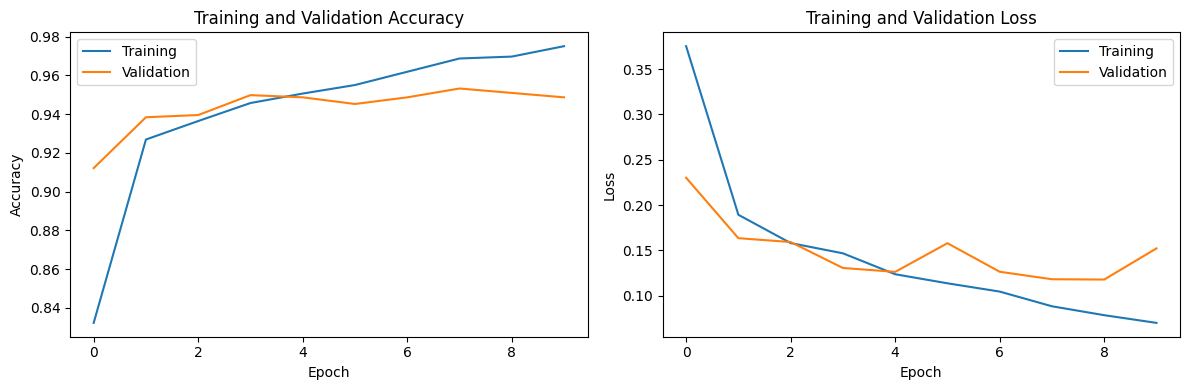

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

probabilities = model.predict(
    X_test,
    batch_size=32,
    verbose=1
).ravel()

predictions = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(
    y_test,
    predictions
)

precision = precision_score(
    y_test,
    predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    predictions,
    zero_division=0
)

auroc = roc_auc_score(
    y_test,
    probabilities
)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUROC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auroc
    ]
})

results

28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step


,Metric,Score
0,Accuracy,0.956621
1,Precision,0.968799
2,Recall,0.971831
3,F1-score,0.970313
4,AUROC,0.981343


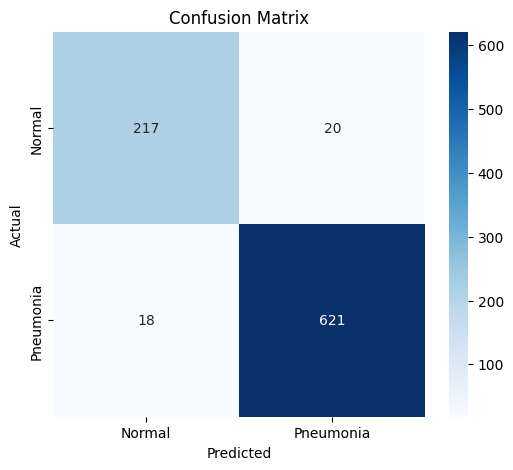

In [19]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Pneumonia"],
    yticklabels=["Normal", "Pneumonia"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Misclassified images: 38


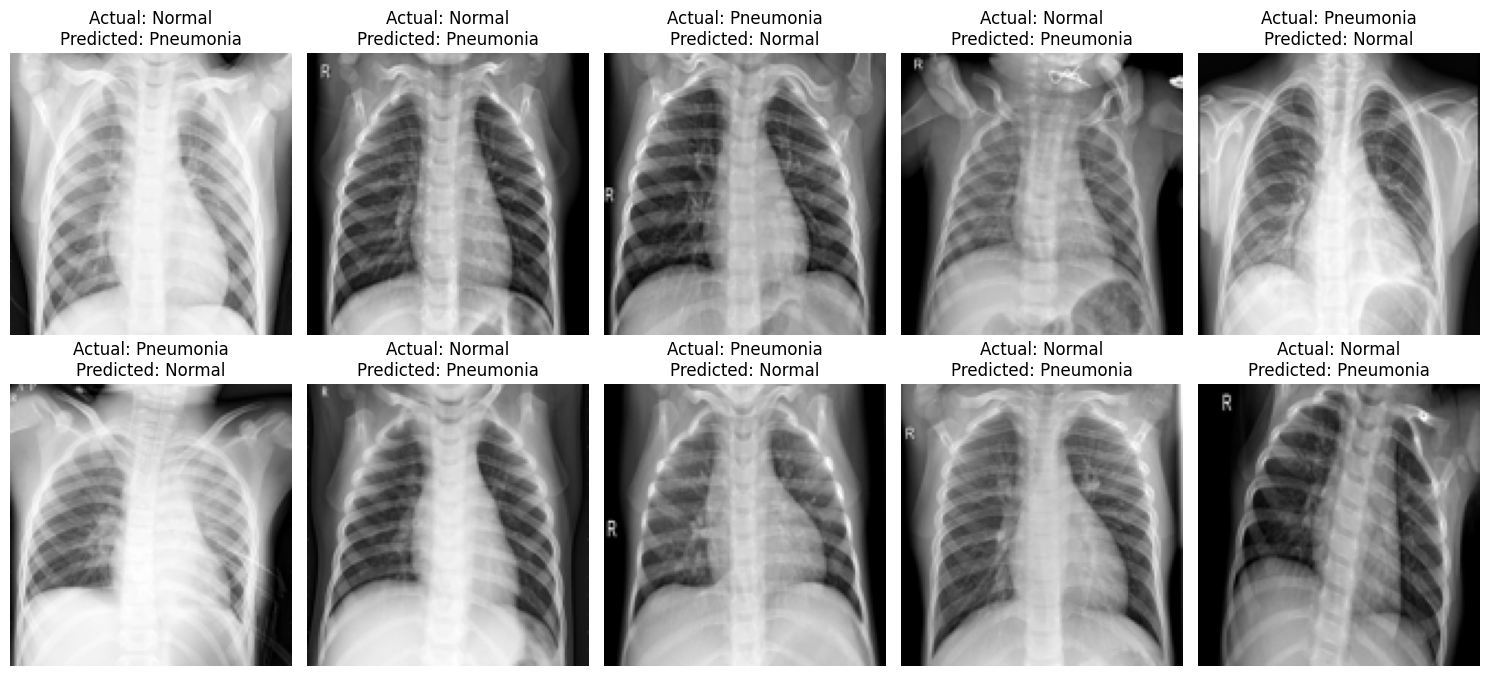

In [20]:
wrong = np.where(
    predictions != y_test
)[0]

print("Misclassified images:", len(wrong))

n = min(10, len(wrong))

plt.figure(figsize=(15, 7))

for i in range(n):

    idx = wrong[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[idx].squeeze(),
        cmap="gray"
    )

    actual = "Pneumonia" if y_test[idx] == 1 else "Normal"
    predicted = "Pneumonia" if predictions[idx] == 1 else "Normal"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        predictions,
        target_names=["Normal", "Pneumonia"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92       237
   Pneumonia       0.97      0.97      0.97       639

    accuracy                           0.96       876
   macro avg       0.95      0.94      0.94       876
weighted avg       0.96      0.96      0.96       876

